In [7]:
import sys
import importlib
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

PROJECT_DIR = Path(r"C:\Users\Nam\Desktop\Palma")
RVFUNCS_DIR = PROJECT_DIR / "Spectral-toolkit-main"
MODEL_DIR = PROJECT_DIR / "Shenar" / "Models"
POWR_DIR = PROJECT_DIR
SPECTRA_DIR = PROJECT_DIR / "spectra"

for directory in reversed([RVFUNCS_DIR, PROJECT_DIR]):
    location = str(directory)
    if location in sys.path:
        sys.path.remove(location)
    sys.path.insert(0, location)

import sb23
import hd195592_common
import rvfuncs

print("sb23:", sb23.__file__)
print("common:", hd195592_common.__file__)


sb23: C:\Users\Nam\Desktop\Palma\sb23.py
common: C:\Users\Nam\Desktop\Palma\hd195592_common.py


In [5]:
spectrum_paths = sorted(SPECTRA_DIR.glob("*.fits"))
if not spectrum_paths:
    raise FileNotFoundError(f"No *.fits spectra found in {SPECTRA_DIR}")

gaussian_spectra = []
for path in spectrum_paths:
    wave, flux, bjd = sb23.read_hermes_inspection(path, verbose=False)
    if bjd is None or not np.isfinite(float(bjd)):
        raise ValueError(f"{path.name}: missing or invalid BJD.")

    gaussian_spectra.append({
        "file": path.name,
        "filename": path.name,
        "wave": wave,
        "flux": flux,
        "bjd": float(bjd),
        "observational": True,
        "kind": "observation",
    })

gaussian_spectra.sort(key=lambda spectrum: (spectrum["bjd"], spectrum["file"]))
for index, spectrum in enumerate(gaussian_spectra, start=1):
    spectrum["label"] = f"E{index:02d}"

required_epochs = {"E05", "E08", "E10", "E11", "E13"}
available_epochs = {spectrum["label"] for spectrum in gaussian_spectra}
missing_epochs = required_epochs - available_epochs
if missing_epochs:
    raise ValueError(f"Required epochs are missing: {sorted(missing_epochs)}")


epoch          BJD                                                                 file
  E05 2.461321e+06 20261007_01185612_HRF_OBJ_ext_CosmicsRemoved_log_merged_cf_norm.fits
  E13 2.461327e+06 20261012_01186141_HRF_OBJ_ext_CosmicsRemoved_log_merged_cf_norm.fits
  E08 2.461324e+06 20261010_01185892_HRF_OBJ_ext_CosmicsRemoved_log_merged_cf_norm.fits
  E10 2.461325e+06 20261011_01186002_HRF_OBJ_ext_CosmicsRemoved_log_merged_cf_norm.fits
  E11 2.461325e+06 20261011_01186014_HRF_OBJ_ext_CosmicsRemoved_log_merged_cf_norm.fits
LOCAL_CONTINUUM=False; explicit shift=0.0 km/s
2G: converged 36/36; near TRAIN modes=1; validating 1 branches.
2G branch 1, E08: joint + independent RV comparison...
2G branch 1, E10: joint + independent RV comparison...
2G branch 1, E11: joint + independent RV comparison...
3G: converged 36/36; near TRAIN modes=2; validating 2 branches.
3G branch 1, E08: joint + independent RV comparison...
3G branch 1, E10: joint + independent RV comparison...
3G branch 1, E11: join

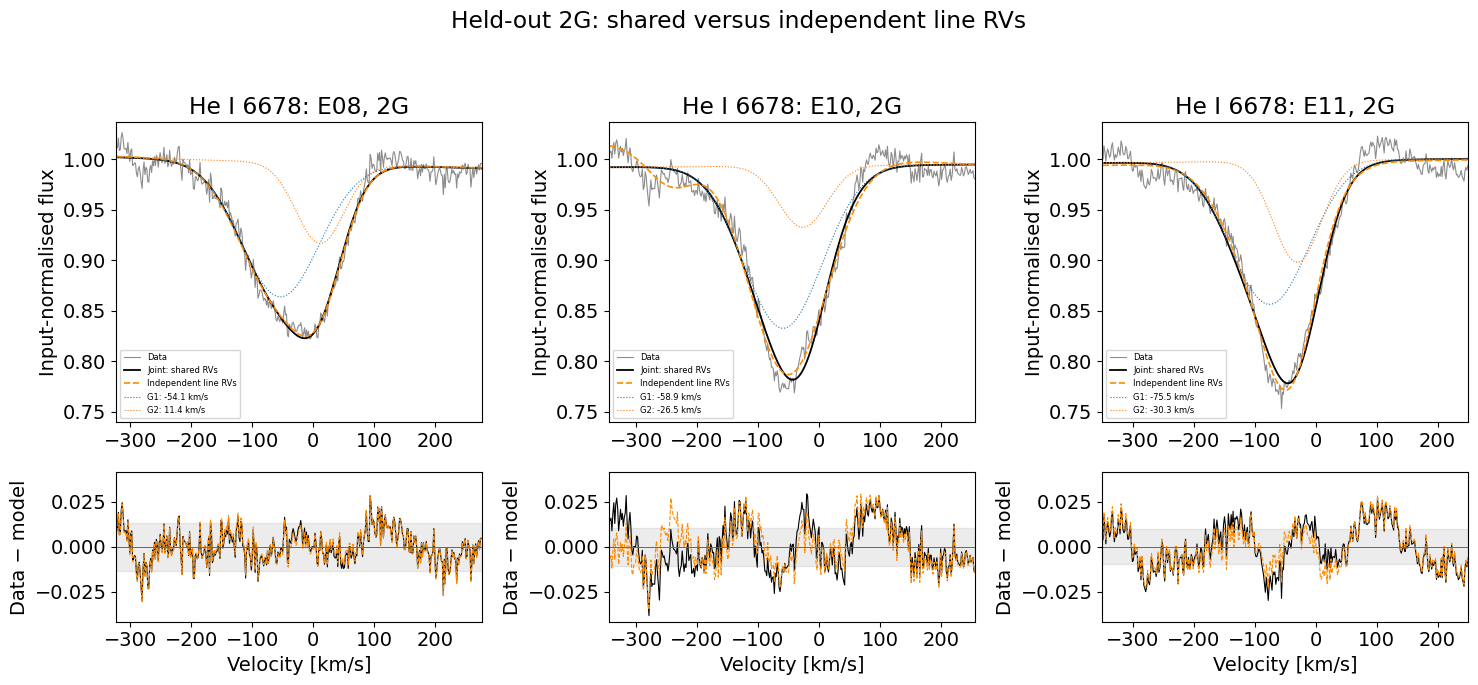

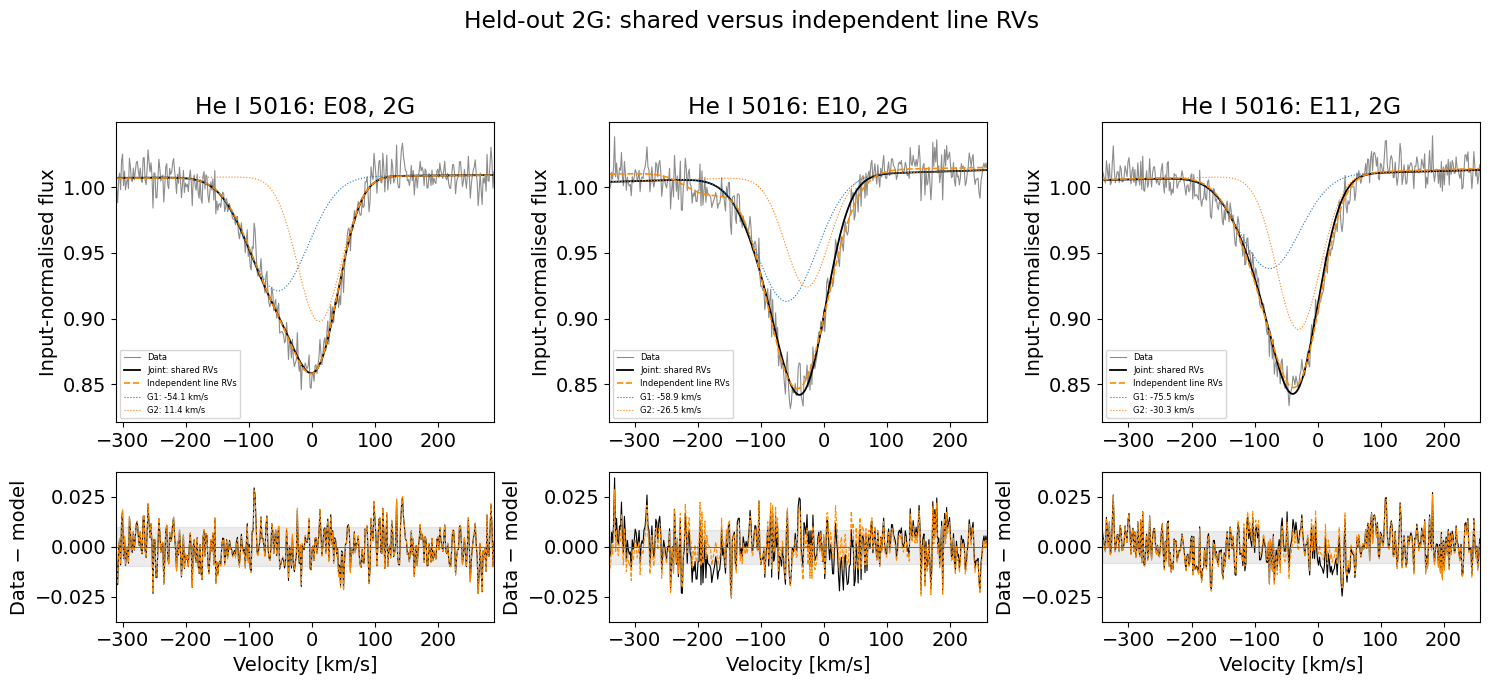

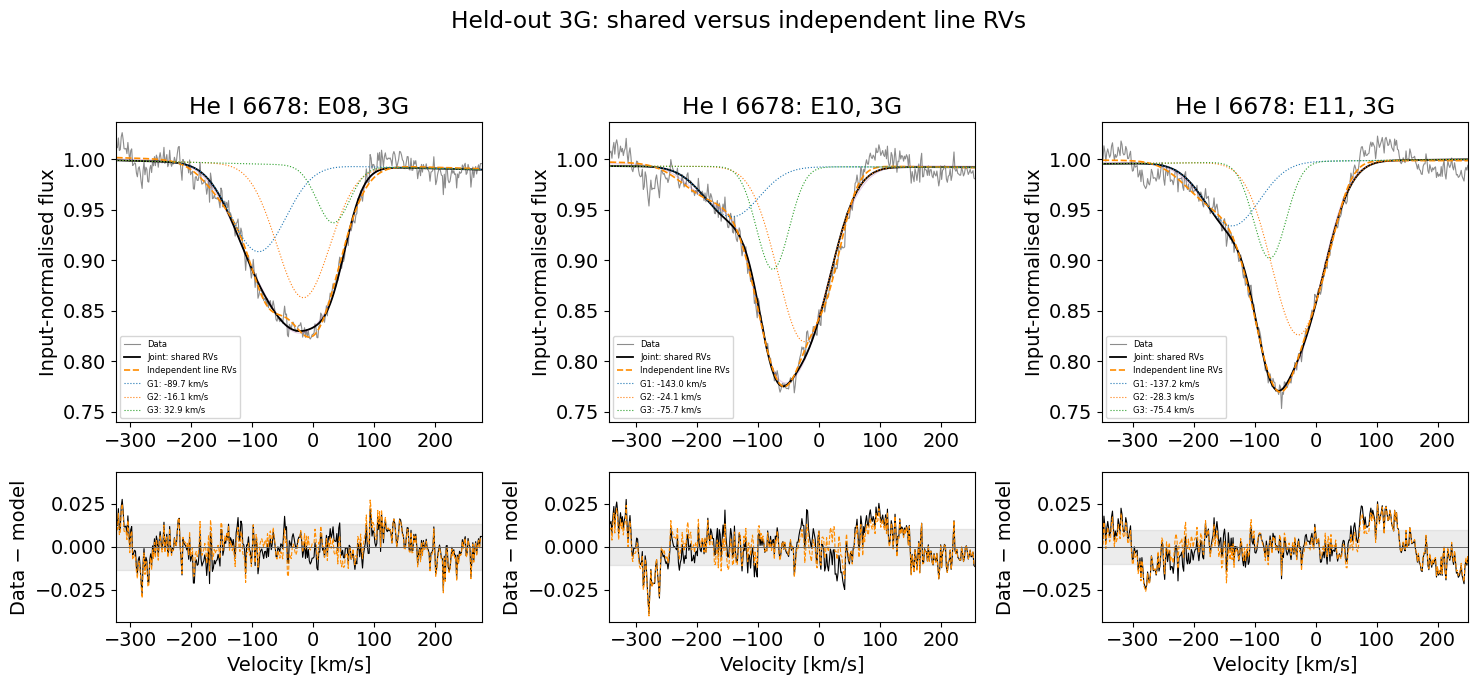

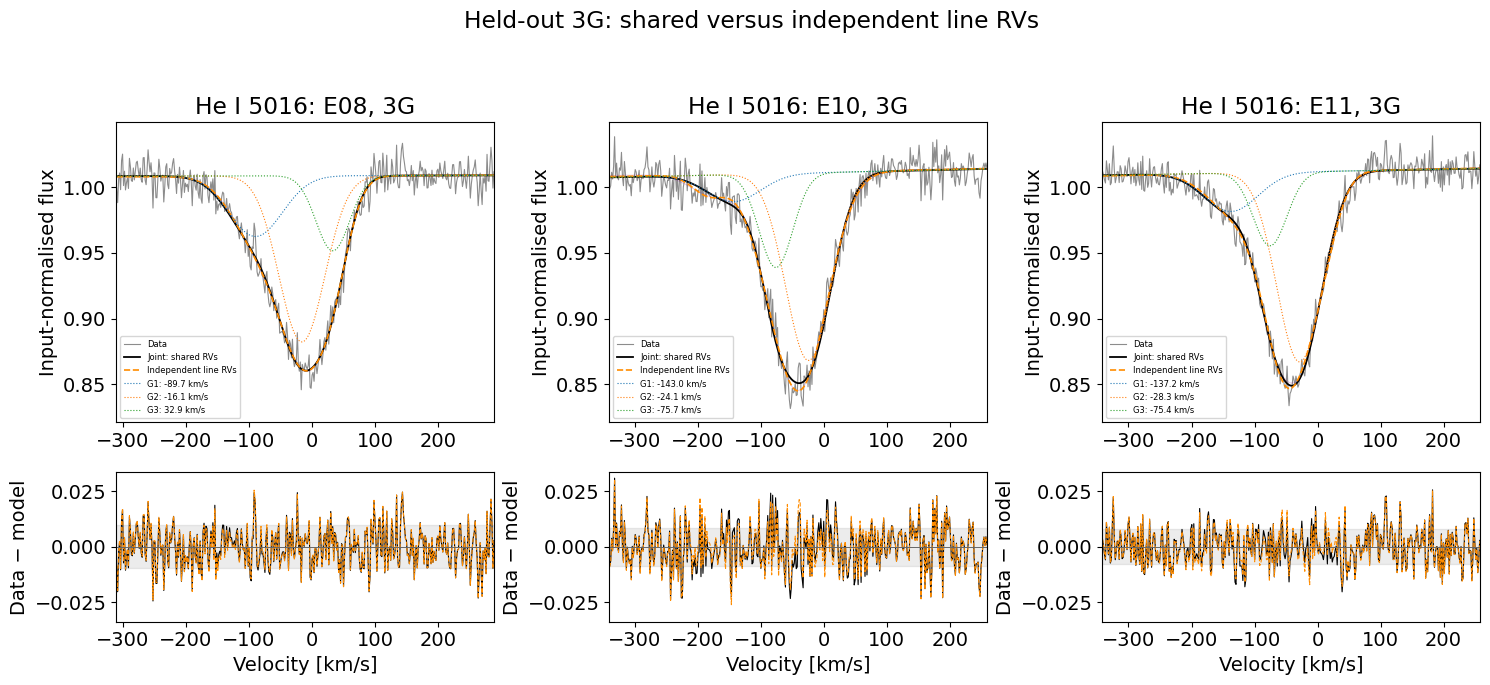

In [6]:
RUN_JOINT_HE = True
TRAIN_EPOCHS = ["E05", "E13"]
VALIDATE_EPOCHS = ["E08", "E10", "E11"]

# Keep 6678 first, matching the joint-fit component-ordering convention.
HE_LINES = {
    "He I 6678": 6678.149,
    "He I 5016": 5015.678,
}
COMPONENT_COUNTS = (2, 3)

GAUSSIAN_CONFIG = sb23.GaussianConfig(
    local_continuum=False,
    gauss_fit_half=160.0,
    fit_half=300.0,
    rv_range=200.0,
    cont_bounds=(240.0, 340.0),
    search_half=200.0,
    additional_shift_kms=0.0,
    n_starts=36,
    seed=35,
)

JOINT_GAUSSIAN_CONFIG = sb23.JointGaussianConfig(
    train_starts=36,
    epoch_starts=24,
    max_nfev=6000,
    seed=351026,
    sigma_bounds=(8.0, 150.0),
    depth_max=0.95,
    cont_offset=0.04,
    cont_tilt=0.04,
    near_delta=10.0,
    max_train_branches=3,
    mode_distance=1.0,
    match_rv=15.0,
    match_sigma=10.0,
    match_depth=0.025,
    core_half=150.0,
    bound_fraction=0.001,
)

GAUSSIAN_RESULTS = None
if RUN_JOINT_HE:
    GAUSSIAN_RESULTS = sb23.run_joint_he(
        gaussian_spectra,
        HE_LINES,
        TRAIN_EPOCHS,
        VALIDATE_EPOCHS,
        COMPONENT_COUNTS,
        GAUSSIAN_CONFIG,
        JOINT_GAUSSIAN_CONFIG,
        make_plots=True,
        verbose=True,
    )
    plt.show()
else:
    print("Joint 2G/3G Gaussian analysis skipped.")

In [9]:

ALL_EPOCHS = [f"E{i:02d}" for i in range(1, 18)]
spectra_by_epoch = {s["label"]: s for s in gaussian_spectra}

missing = set(ALL_EPOCHS) - set(spectra_by_epoch)
if missing:
    raise ValueError(f"Missing epochs: {sorted(missing)}")

HE6678_PROFILES = {
    epoch: sb23.measure_profile(
        spectra_by_epoch[epoch],
        6678.149,
        GAUSSIAN_CONFIG,
    )
    for epoch in ALL_EPOCHS
}

print(f"Prepared {len(HE6678_PROFILES)} He I 6678 profiles.")

Prepared 17 He I 6678 profiles.


In [10]:
def fit_6678_variable_depth(profiles, n_components, gaussian_config,
                            joint_config, *, n_starts=None):
    """
    Fit one line across all epochs.

    Shared across epochs:
      - Gaussian component widths

    Free for each epoch:
      - component RVs
      - component depths
      - small continuum offset and slope

    Component labels are matched across alternative fit modes; they are not
    interpreted as stellar identities.
    """
    if n_components not in (2, 3):
        raise ValueError("n_components must be 2 or 3.")

    epochs = list(profiles)
    n_epoch = len(epochs)
    n_comp = n_components
    centres = np.array([profiles[e]["rv"] for e in epochs])

    if n_starts is None:
        n_starts = joint_config.train_starts

    def unpack(theta):
        i = 0

        sigma = theta[i:i + n_comp].reshape(1, n_comp)
        i += n_comp

        rv = theta[i:i + n_epoch * n_comp].reshape(n_epoch, 1, n_comp)
        i += n_epoch * n_comp

        depth = theta[i:i + n_epoch * n_comp].reshape(n_epoch, 1, n_comp)
        i += n_epoch * n_comp

        cont = theta[i:].reshape(n_epoch, 1, 2)

        return {
            "sigma": sigma,
            "rv": rv,
            "depth": depth,
            "cont": cont,
        }

    rv_lower = np.repeat(
        (centres - gaussian_config.rv_range)[:, None], n_comp, axis=1
    )
    rv_upper = np.repeat(
        (centres + gaussian_config.rv_range)[:, None], n_comp, axis=1
    )

    lower = np.concatenate([
        np.full(n_comp, joint_config.sigma_bounds[0]),
        rv_lower.ravel(),
        np.zeros(n_epoch * n_comp),
        np.tile(
            [1 - joint_config.cont_offset, -joint_config.cont_tilt],
            n_epoch,
        ),
    ])
    upper = np.concatenate([
        np.full(n_comp, joint_config.sigma_bounds[1]),
        rv_upper.ravel(),
        np.full(n_epoch * n_comp, joint_config.depth_max),
        np.tile(
            [1 + joint_config.cont_offset, joint_config.cont_tilt],
            n_epoch,
        ),
    ])

    def residual(theta):
        state = unpack(theta)
        pieces = []

        for epoch_index, epoch in enumerate(epochs):
            profile = profiles[epoch]
            shape = np.column_stack([
                state["depth"][epoch_index, 0],
                state["sigma"][0],
            ]).ravel()

            continuum, tilt = state["cont"][epoch_index, 0]
            model = (
                continuum
                + tilt * (profile["v"] - profile["rv"]) / gaussian_config.fit_half
                - sb23.gaussian_terms(
                    profile["v"],
                    shape,
                    state["rv"][epoch_index, 0],
                ).sum(axis=0)
            )
            pieces.append((model - profile["f"]) / profile["noise"])

        return np.concatenate(pieces)

    rng = np.random.default_rng(joint_config.seed + 100 * n_comp)
    starts = []

    separations = [0.0, 40.0, 80.0, 120.0, 160.0]

    for start_index in range(n_starts):
        sigma_start = rng.uniform(25.0, 95.0, n_comp)
        rv_start = np.empty((n_epoch, n_comp))
        depth_start = np.empty((n_epoch, n_comp))
        cont_start = np.zeros((n_epoch, 2))
        cont_start[:, 0] = 1.0

        for epoch_index, epoch in enumerate(epochs):
            profile = profiles[epoch]
            separation = separations[start_index % len(separations)]
            offsets = np.linspace(-0.5, 0.5, n_comp) * separation
            rng.shuffle(offsets)
            rv_start[epoch_index] = profile["rv"] + offsets

            absorption_strength = np.clip(
                1 - np.percentile(profile["f"], 5),
                0.02,
                0.8,
            )
            depth_start[epoch_index] = (
                absorption_strength * rng.dirichlet(np.full(n_comp, 1.5))
            )

        starts.append(np.concatenate([
            sigma_start,
            rv_start.ravel(),
            depth_start.ravel(),
            cont_start.ravel(),
        ]))

    result = sb23.solve_multistart(
        residual,
        starts,
        lower,
        upper,
        max_nfev=joint_config.max_nfev,
        require_success=True,
    )

    # Attach decoded states so the existing branch/mode matcher can be used.
    for solution in result["solutions"]:
        solution["state"] = unpack(solution["theta"])

    modes = sb23.j_modes(result, joint_config)
    if not modes:
        raise RuntimeError("No retained fit modes.")

    # Set a single global component ordering from the best mode, then match
    # other modes to it. Never reorder components independently by epoch RV.
    reference = modes[0]["state"]
    mean_area_proxy = (
        reference["depth"][:, 0, :].mean(axis=0) * reference["sigma"][0]
    )
    reference = sb23.j_reorder(
        reference,
        np.argsort(-mean_area_proxy),
    )

    for mode in modes:
        mode["state"], mode["match_distance"] = sb23.j_match(
            mode["state"],
            reference,
            joint_config,
        )

    rows = []
    for mode_index, mode in enumerate(modes, start=1):
        state = mode["state"]

        for epoch_index, epoch in enumerate(epochs):
            profile = profiles[epoch]
            row = {
                "mode": mode_index,
                "delta_chi2": mode["chi2"] - result["best"]["chi2"],
                "starts_in_mode": mode["start_count"],
                "match_distance": mode["match_distance"],
                "epoch": epoch,
                "BJD": profile["bjd"],
                "continuum": state["cont"][epoch_index, 0, 0],
                "continuum_tilt": state["cont"][epoch_index, 0, 1],
            }

            for component in range(n_comp):
                row[f"G{component + 1}_RV"] = state["rv"][
                    epoch_index, 0, component
                ]
                row[f"G{component + 1}_depth"] = state["depth"][
                    epoch_index, 0, component
                ]
                row[f"G{component + 1}_sigma"] = state["sigma"][0, component]

            rows.append(row)

    return {
        "fit": result,
        "modes": modes,
        "table": pd.DataFrame(rows),
        "epochs": epochs,
        "profiles": profiles,
    }

In [11]:
HE6678_VARIABLE_DEPTH = {}

for n_components in (2, 3):
    print(f"Fitting He I 6678 with {n_components} Gaussians across all epochs...")
    HE6678_VARIABLE_DEPTH[n_components] = fit_6678_variable_depth(
        HE6678_PROFILES,
        n_components,
        GAUSSIAN_CONFIG,
        JOINT_GAUSSIAN_CONFIG,
        n_starts=JOINT_GAUSSIAN_CONFIG.train_starts,
    )

    result = HE6678_VARIABLE_DEPTH[n_components]
    print(
        f"{n_components}G: "
        f"{len(result['fit']['solutions'])} converged starts; "
        f"{len(result['modes'])} retained near-best modes."
    )

HE6678_TRACK_TABLE = pd.concat(
    [
        result["table"].assign(model=f"{n_components}G")
        for n_components, result in HE6678_VARIABLE_DEPTH.items()
    ],
    ignore_index=True,
)

display(
    HE6678_TRACK_TABLE.sort_values(
        ["model", "mode", "BJD"]
    ).reset_index(drop=True)
)

Fitting He I 6678 with 2 Gaussians across all epochs...
2G: 36 converged starts; 1 retained near-best modes.
Fitting He I 6678 with 3 Gaussians across all epochs...
3G: 36 converged starts; 1 retained near-best modes.


,mode,delta_chi2,starts_in_mode,match_distance,epoch,BJD,continuum,continuum_tilt,G1_RV,G1_depth,G1_sigma,G2_RV,G2_depth,G2_sigma,model,G3_RV,G3_depth,G3_sigma
0,1,0.0,8,0.0,E01,2.461319e+06,0.993357,0.004334,-52.769058,0.152154,54.699191,15.118486,0.054257,33.120294,2G,NaN,NaN,NaN
1,1,0.0,8,0.0,E02,2.461319e+06,0.995976,0.003899,-52.684891,0.151286,54.699191,5.947297,0.049854,33.120294,2G,NaN,NaN,NaN
2,1,0.0,8,0.0,E03,2.461320e+06,0.995819,-0.000042,-44.801680,0.148740,54.699191,2.809337,0.047617,33.120294,2G,NaN,NaN,NaN
3,1,0.0,8,0.0,E04,2.461320e+06,0.996278,-0.000189,-40.108152,0.148007,54.699191,7.050436,0.044617,33.120294,2G,NaN,NaN,NaN
4,1,0.0,8,0.0,E05,2.461321e+06,0.991727,-0.003609,-32.385820,0.110287,54.699191,30.833261,0.111914,33.120294,2G,NaN,NaN,NaN
5,1,0.0,8,0.0,E06,2.461323e+06,0.997251,-0.004630,-72.898197,0.161142,54.699191,3.646477,0.088544,33.120294,2G,NaN,NaN,NaN
6,1,0.0,8,0.0,E07,2.461324e+06,1.000413,-0.001793,-72.375316,0.155604,54.699191,5.828318,0.096752,33.120294,2G,NaN,NaN,NaN
7,1,0.0,8,0.0,E08,2.461324e+06,0.994421,-0.004627,-57.839457,0.143732,54.699191,19.376694,0.098074,33.120294,2G,NaN,NaN,NaN
8,1,0.0,8,0.0,E09,2.461324e+06,0.993289,-0.005493,-57.119484,0.145044,54.699191,23.145258,0.098993,33.120294,2G,NaN,NaN,NaN
9,1,0.0,8,0.0,E10,2.461325e+06,0.990892,0.002912,-55.320434,0.202029,54.699191,8.567689,0.029836,33.120294,2G,NaN,NaN,NaN


In [21]:
with pd.option_context("display.float_format", lambda x: f"{x:.8f}"):
    HE6678_TRACK_TABLE[[
        "model", "epoch", "BJD",
        "G1_RV", "G2_RV", "G3_RV",
    ]].sort_values(["model", "BJD"]).to_csv(
        "HE6678_TRACK_TABLE.csv",
        index=False,
        float_format="%.8f"
    )

In [22]:
import os
print(os.path.abspath("HE6678_TRACK_TABLE.csv"))

c:\Users\Nam\Desktop\Palma\HE6678_TRACK_TABLE.csv


,model,n_epochs,gamma_kms,K_kms,Tmax_BJD,RMS_sine_kms,RMS_constant_kms
0,2G,17,-55.634936,6.103958,2.461325e+06,9.791573,10.657640
1,3G,17,-51.504745,4.894918,2.461325e+06,9.039836,9.640963


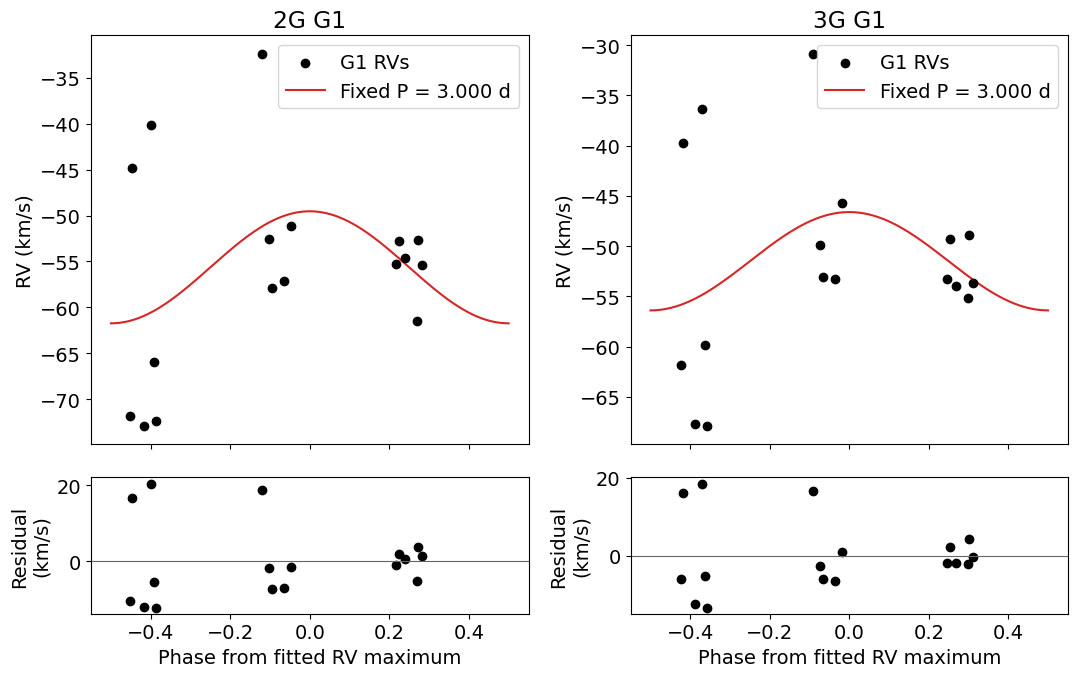

In [16]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Use the name of your DataFrame here if it differs.
rv_table = HE6678_TRACK_TABLE
PERIOD_D = 3

def fit_fixed_period_g1(group, period_d=PERIOD_D):
    group = group.dropna(subset=["BJD", "G1_RV"]).sort_values("BJD")
    t = group["BJD"].to_numpy(float)
    rv = group["G1_RV"].to_numpy(float)

    # Center times to avoid numerical precision problems with large BJDs.
    t_ref = t.mean()
    angle = 2 * np.pi * (t - t_ref) / period_d
    design = np.column_stack([
        np.ones_like(t),
        np.sin(angle),
        np.cos(angle),
    ])

    gamma, sin_coeff, cos_coeff = np.linalg.lstsq(
        design, rv, rcond=None
    )[0]
    fitted = design @ np.array([gamma, sin_coeff, cos_coeff])
    residual = rv - fitted

    semi_amplitude = np.hypot(sin_coeff, cos_coeff)
    phase_offset = np.arctan2(cos_coeff, sin_coeff)

    # Epoch of maximum RV for this fitted sinusoid.
    phase_of_max = (0.25 - phase_offset / (2 * np.pi)) % 1
    t_max = t_ref + phase_of_max * period_d

    # Fold so phase 0 is the fitted RV maximum, in [-0.5, 0.5).
    phase = (t - t_max + period_d / 2) % period_d / period_d - 0.5

    constant = np.full_like(rv, rv.mean())

    return {
        "n": len(rv),
        "gamma_kms": gamma,
        "K_kms": semi_amplitude,
        "t_max_BJD": t_max,
        "rms_sine_kms": np.sqrt(np.mean(residual**2)),
        "rms_constant_kms": np.sqrt(np.mean((rv - constant)**2)),
        "phase": phase,
        "rv": rv,
        "fitted": fitted,
        "residual": residual,
    }


fits = {}
summary = []

fig, axes = plt.subplots(
    2, 2, figsize=(11, 7), sharex="col",
    gridspec_kw={"height_ratios": [3, 1]},
)

for row, model in enumerate(("2G", "3G")):
    group = rv_table[rv_table["model"] == model]
    result = fit_fixed_period_g1(group)
    fits[model] = result

    summary.append({
        "model": model,
        "n_epochs": result["n"],
        "gamma_kms": result["gamma_kms"],
        "K_kms": result["K_kms"],
        "Tmax_BJD": result["t_max_BJD"],
        "RMS_sine_kms": result["rms_sine_kms"],
        "RMS_constant_kms": result["rms_constant_kms"],
    })

    # Smooth fitted curve as a function of folded phase.
    phase_grid = np.linspace(-0.5, 0.5, 500)
    curve = result["gamma_kms"] + result["K_kms"] * np.cos(
        2 * np.pi * phase_grid
    )

    ax = axes[0, row]
    ax.scatter(result["phase"], result["rv"], color="black", zorder=3,
               label="G1 RVs")
    ax.plot(phase_grid, curve, color="tab:red",
            label=f"Fixed P = {PERIOD_D:.3f} d")
    ax.set_title(f"{model} G1")
    ax.set_ylabel("RV (km/s)")
    ax.legend()

    rax = axes[1, row]
    rax.axhline(0, color="0.4", lw=0.8)
    rax.scatter(result["phase"], result["residual"], color="black")
    rax.set_xlabel("Phase from fitted RV maximum")
    rax.set_ylabel("Residual\n(km/s)")

plt.tight_layout()
display(pd.DataFrame(summary))
plt.show()

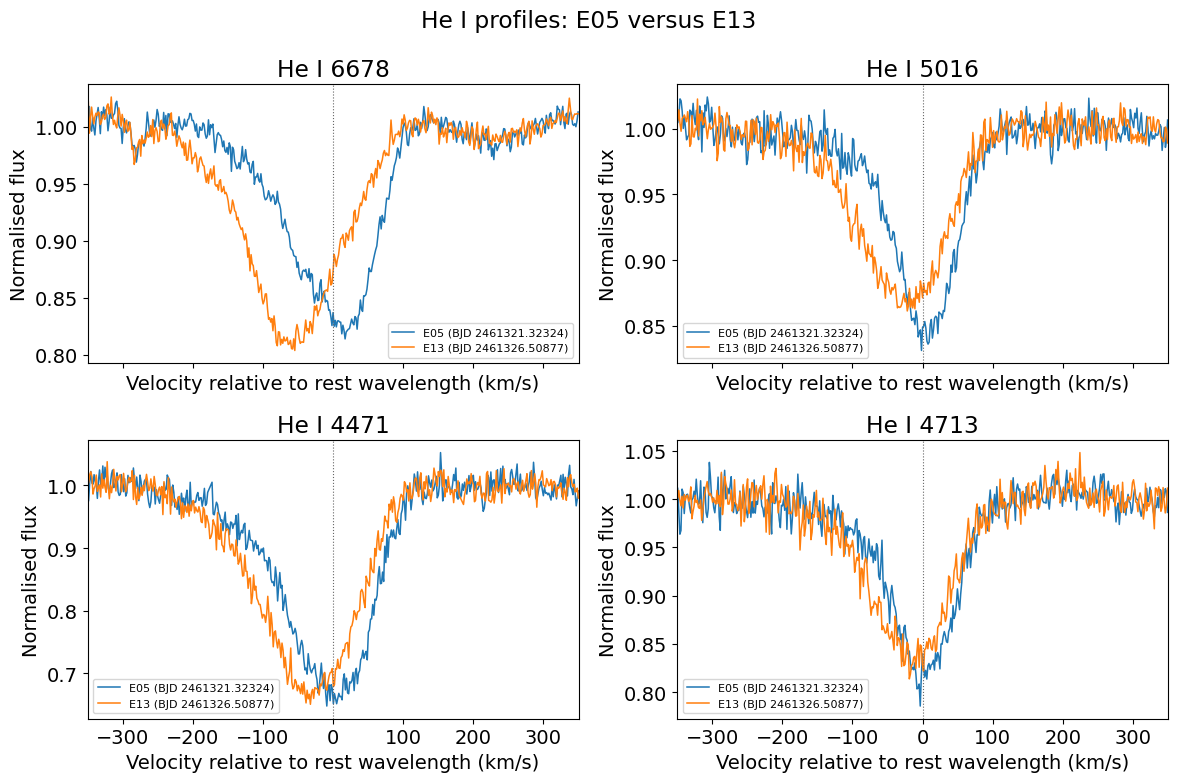

In [17]:
import numpy as np
import matplotlib.pyplot as plt
import sb23

spectra_by_epoch = {s["label"]: s for s in gaussian_spectra}

HE_LINE_REST_A = {
    "He I 6678": 6678.149,
    "He I 5016": 5015.678,
    "He I 4471": 4471.479,
    "He I 4713": 4713.146,
}

PLOT_HALF_WIDTH = 350.0  # km/s
PLOT_LOCAL_CONTINUUM = True

def get_epoch_line_profile(epoch, line_name):
    spectrum = spectra_by_epoch[epoch]
    rest = HE_LINE_REST_A[line_name]

    v = sb23.wavelength_to_velocity(
        spectrum["wave"],
        rest,
        shift_kms=GAUSSIAN_CONFIG.additional_shift_kms,
    )
    flux = np.asarray(spectrum["flux"], dtype=float)

    use = np.abs(v) <= PLOT_HALF_WIDTH
    v, flux = v[use], flux[use]

    if PLOT_LOCAL_CONTINUUM:
        flux = sb23.normalise_locally(
            v, flux, centre=0.0,
            cont_bounds=GAUSSIAN_CONFIG.cont_bounds,
        )

    return v, flux, spectrum.get("bjd")

fig, axes = plt.subplots(2, 2, figsize=(12, 8), sharex=True)
axes = axes.ravel()

for ax, line_name in zip(axes, HE_LINE_REST_A):
    for epoch, color in [("E05", "tab:blue"), ("E13", "tab:orange")]:
        v, flux, bjd = get_epoch_line_profile(epoch, line_name)
        ax.plot(v, flux, color=color, lw=1.1,
                label=f"{epoch} (BJD {bjd:.5f})")

    ax.axvline(0, color="0.4", ls=":", lw=0.8)
    ax.set_title(line_name)
    ax.set_xlim(-PLOT_HALF_WIDTH, PLOT_HALF_WIDTH)
    ax.set_xlabel("Velocity relative to rest wavelength (km/s)")
    ax.set_ylabel("Normalised flux")
    ax.legend(fontsize=8)

fig.suptitle("He I profiles: E05 versus E13")
fig.tight_layout()
plt.show()

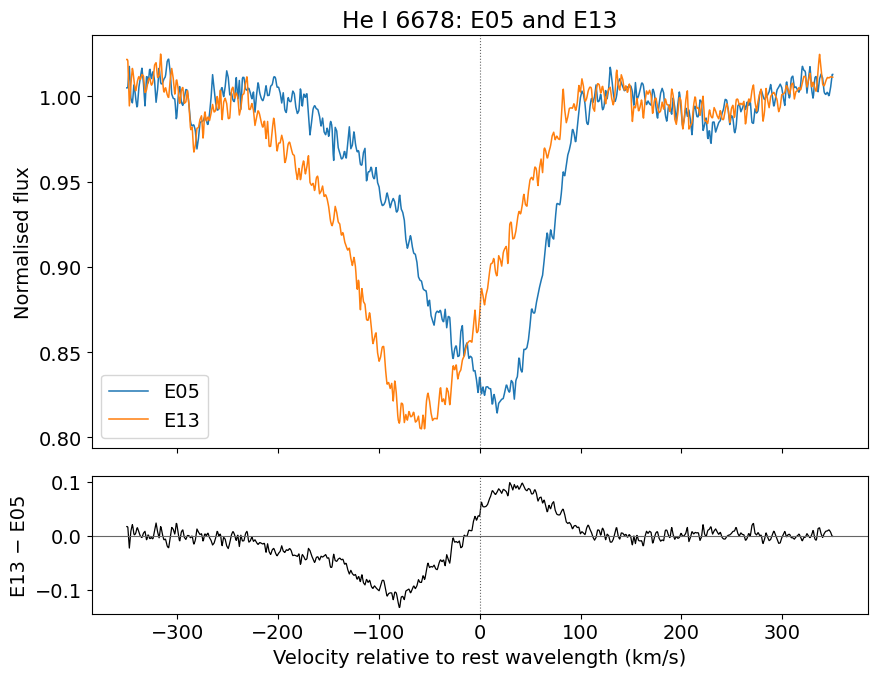

In [18]:
line_name = "He I 6678"
v05, f05, _ = get_epoch_line_profile("E05", line_name)
v13, f13, _ = get_epoch_line_profile("E13", line_name)

v_common = np.linspace(-PLOT_HALF_WIDTH, PLOT_HALF_WIDTH, 1400)
f05_common = np.interp(v_common, v05, f05)
f13_common = np.interp(v_common, v13, f13)
difference = f13_common - f05_common

fig, (ax, dax) = plt.subplots(
    2, 1, figsize=(9, 7), sharex=True,
    gridspec_kw={"height_ratios": [3, 1]},
)

ax.plot(v_common, f05_common, color="tab:blue", lw=1.1, label="E05")
ax.plot(v_common, f13_common, color="tab:orange", lw=1.1, label="E13")
ax.axvline(0, color="0.4", ls=":", lw=0.8)
ax.set_ylabel("Normalised flux")
ax.set_title("He I 6678: E05 and E13")
ax.legend()

dax.plot(v_common, difference, color="black", lw=0.9)
dax.axhline(0, color="0.4", lw=0.8)
dax.axvline(0, color="0.4", ls=":", lw=0.8)
dax.set_xlabel("Velocity relative to rest wavelength (km/s)")
dax.set_ylabel("E13 − E05")

fig.tight_layout()
plt.show()


E05
  2G:
    G1: RV=-32.4 km/s, depth=0.110, sigma=54.7 km/s
    G2: RV=30.8 km/s, depth=0.112, sigma=33.1 km/s
  3G:
    G1: RV=-30.9 km/s, depth=0.116, sigma=51.9 km/s
    G2: RV=-192.5 km/s, depth=0.007, sigma=121.8 km/s
    G3: RV=33.0 km/s, depth=0.113, sigma=31.8 km/s

E13
  2G:
    G1: RV=-65.9 km/s, depth=0.183, sigma=54.7 km/s
    G2: RV=18.3 km/s, depth=0.041, sigma=33.1 km/s
  3G:
    G1: RV=-59.8 km/s, depth=0.178, sigma=51.9 km/s
    G2: RV=-179.9 km/s, depth=0.040, sigma=121.8 km/s
    G3: RV=27.0 km/s, depth=0.041, sigma=31.8 km/s


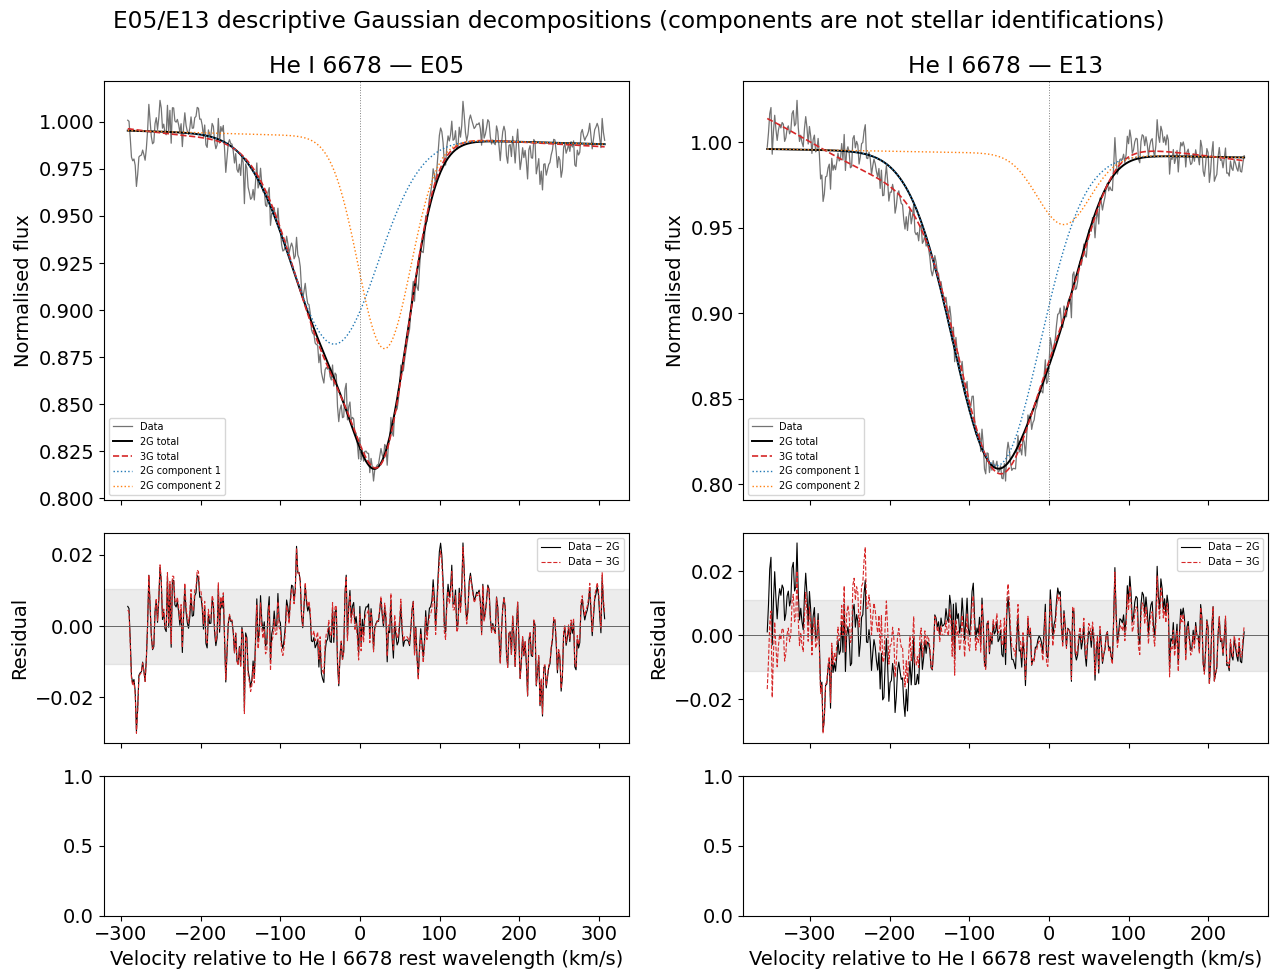

In [19]:
def model_and_terms_from_state(result, n_components, epoch):
    mode = result["modes"][0]
    state = mode["state"]
    epoch_index = result["epochs"].index(epoch)
    profile = result["profiles"][epoch]

    sigma = state["sigma"][0]
    depths = state["depth"][epoch_index, 0]
    rvs = state["rv"][epoch_index, 0]
    c0, tilt = state["cont"][epoch_index, 0]

    shape = np.column_stack([depths, sigma]).ravel()
    terms = sb23.gaussian_terms(profile["v"], shape, rvs)
    continuum = c0 + tilt * (
        profile["v"] - profile["rv"]
    ) / GAUSSIAN_CONFIG.fit_half
    model = continuum - terms.sum(axis=0)

    return profile, state, continuum, terms, model


fig, axes = plt.subplots(
    3, 2, figsize=(13, 10), sharex="col",
    gridspec_kw={"height_ratios": [3, 1.5, 1]},
)

component_colors = ["tab:blue", "tab:orange", "tab:green"]

for col, epoch in enumerate(("E05", "E13")):
    result_2g = HE6678_VARIABLE_DEPTH[2]
    result_3g = HE6678_VARIABLE_DEPTH[3]

    p2, state2, cont2, terms2, model2 = model_and_terms_from_state(
        result_2g, 2, epoch
    )
    p3, state3, cont3, terms3, model3 = model_and_terms_from_state(
        result_3g, 3, epoch
    )

    ax = axes[0, col]
    ax.plot(p2["v"], p2["f"], color="0.45", lw=0.9, label="Data")
    ax.plot(p2["v"], model2, color="black", lw=1.4, label="2G total")
    ax.plot(p3["v"], model3, color="tab:red", ls="--", lw=1.2, label="3G total")

    # Each curve is continuum minus one Gaussian component. These are
    # descriptive components and should not be labelled as individual stars.
    for j, term in enumerate(terms2):
        ax.plot(
            p2["v"], cont2 - term, ls=":", lw=1.0,
            color=component_colors[j],
            label=f"2G component {j + 1}",
        )

    ax.axvline(0, color="0.5", ls=":", lw=0.7)
    ax.set_title(f"He I 6678 — {epoch}")
    ax.set_ylabel("Normalised flux")
    ax.legend(fontsize=7)

    # Show residuals for the two model complexities.
    axes[1, col].plot(p2["v"], p2["f"] - model2,
                      color="black", lw=0.8, label="Data − 2G")
    axes[1, col].plot(p3["v"], p3["f"] - model3,
                      color="tab:red", ls="--", lw=0.8, label="Data − 3G")
    axes[1, col].axhline(0, color="0.4", lw=0.7)
    axes[1, col].axhspan(-p2["noise"], p2["noise"], color="0.5", alpha=0.15)
    axes[1, col].set_ylabel("Residual")
    axes[1, col].legend(fontsize=7)

    # Print the fitted component parameters for these two epochs.
    print(f"\n{epoch}")
    for n_components, result in [(2, result_2g), (3, result_3g)]:
        _, state, _, _, _ = model_and_terms_from_state(
            result, n_components, epoch
        )
        i = result["epochs"].index(epoch)
        print(f"  {n_components}G:")
        for j in range(n_components):
            print(
                f"    G{j + 1}: RV={state['rv'][i, 0, j]:.1f} km/s, "
                f"depth={state['depth'][i, 0, j]:.3f}, "
                f"sigma={state['sigma'][0, j]:.1f} km/s"
            )

for ax in axes[-1, :]:
    ax.set_xlabel("Velocity relative to He I 6678 rest wavelength (km/s)")

fig.suptitle(
    "E05/E13 descriptive Gaussian decompositions "
    "(components are not stellar identifications)"
)
fig.tight_layout()
plt.show()

#### Trailed Spectra

In [21]:
import sys
import warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

PROJECT_DIR = Path(r"C:\Users\Nam\Desktop\Palma")
if str(PROJECT_DIR) not in sys.path:
    sys.path.insert(0, str(PROJECT_DIR))

import sb23
import hd195592_common as common

SPECTRA_DIR = PROJECT_DIR / "spectra"

LINES = {
    "He I 4026":   4026.19,
    "He I 4388":   4387.93,
    "He I 4471":   4471.48,
    "He I 4713":   4713.14,
    "He I 6678":   6678.15,
    "He I 5016":   5015.68,
    "Si IV 4089":  4088.86,
    "Si III 4552": 4552.62,
    "Si III 4567": 4567.84,

}

ROWS = ["flux", "residual"]      # remove one entry for a single row
VIEW_HALF = 400.0                # km/s either side of each rest wavelength
DV = 2.0                         # velocity grid step [km/s]
TIME_STEP_DAYS = 0.05            # display grid for the filled image
MAX_FILL_DISTANCE_DAYS = 0.5     # blank anything farther than this from a real epoch
RESIDUAL_LIMIT = None            # None = automatic per line; or e.g. 0.03 for a common scale

spectra = sb23.load_spectra(SPECTRA_DIR, pattern="*.fits")
labels = [s["label"] for s in spectra]
bjd = np.array([s["bjd"] for s in spectra], float)
display(pd.DataFrame({"epoch": labels, "BJD": bjd,
                      "gap_to_previous_d": np.r_[np.nan, np.diff(bjd)]}))

grid = np.arange(-VIEW_HALF, VIEW_HALF + DV, DV)
n_t = int(np.ceil((bjd[-1] - bjd[0]) / TIME_STEP_DAYS)) + 1
t_grid = np.linspace(bjd[0], bjd[-1], n_t)

hi = np.clip(np.searchsorted(bjd, t_grid, side="right"), 1, len(bjd) - 1)
lo = hi - 1
weight = np.clip((t_grid - bjd[lo]) / (bjd[hi] - bjd[lo]), 0, 1)
nearest = np.minimum(t_grid - bjd[lo], bjd[hi] - t_grid)
too_far = nearest > MAX_FILL_DISTANCE_DAYS

DYN = {}
for name, rest in LINES.items():
    rows = []
    for s in spectra:
        v = common.wavelength_to_velocity(s["wave"], rest)
        order = np.argsort(v)
        rows.append(np.interp(grid, v[order], s["flux"][order],
                              left=np.nan, right=np.nan))
    flux = np.vstack(rows)                       # real epochs only
    covered = bool(np.isfinite(flux).any())
    if covered:
        with warnings.catch_warnings():
            warnings.simplefilter("ignore", RuntimeWarning)
            median_profile = np.nanmedian(flux, axis=0)
        filled = (1 - weight)[:, None] * flux[lo] + weight[:, None] * flux[hi]
        filled[too_far] = np.nan
        DYN[name] = {"flux": flux, "filled": filled,
                     "filled_resid": filled - median_profile, "covered": True}
    else:
        DYN[name] = {"covered": False}
        print(f"{name}: no spectral coverage in the displayed window.")

print(f"{np.sum(~too_far)}/{len(t_grid)} display rows are within "
      f"{MAX_FILL_DISTANCE_DAYS} d of a real epoch; the rest are blank (grey).")

,epoch,BJD,gap_to_previous_d
0,E01,2.461319e+06,NaN
1,E02,2.461319e+06,0.142475
2,E03,2.461320e+06,0.844911
3,E04,2.461320e+06,0.144092
4,E05,2.461321e+06,0.836154
5,E06,2.461323e+06,2.107629
6,E07,2.461324e+06,0.095353
7,E08,2.461324e+06,0.870692
8,E09,2.461324e+06,0.091173
9,E10,2.461325e+06,0.845157


163/185 display rows are within 0.5 d of a real epoch; the rest are blank (grey).


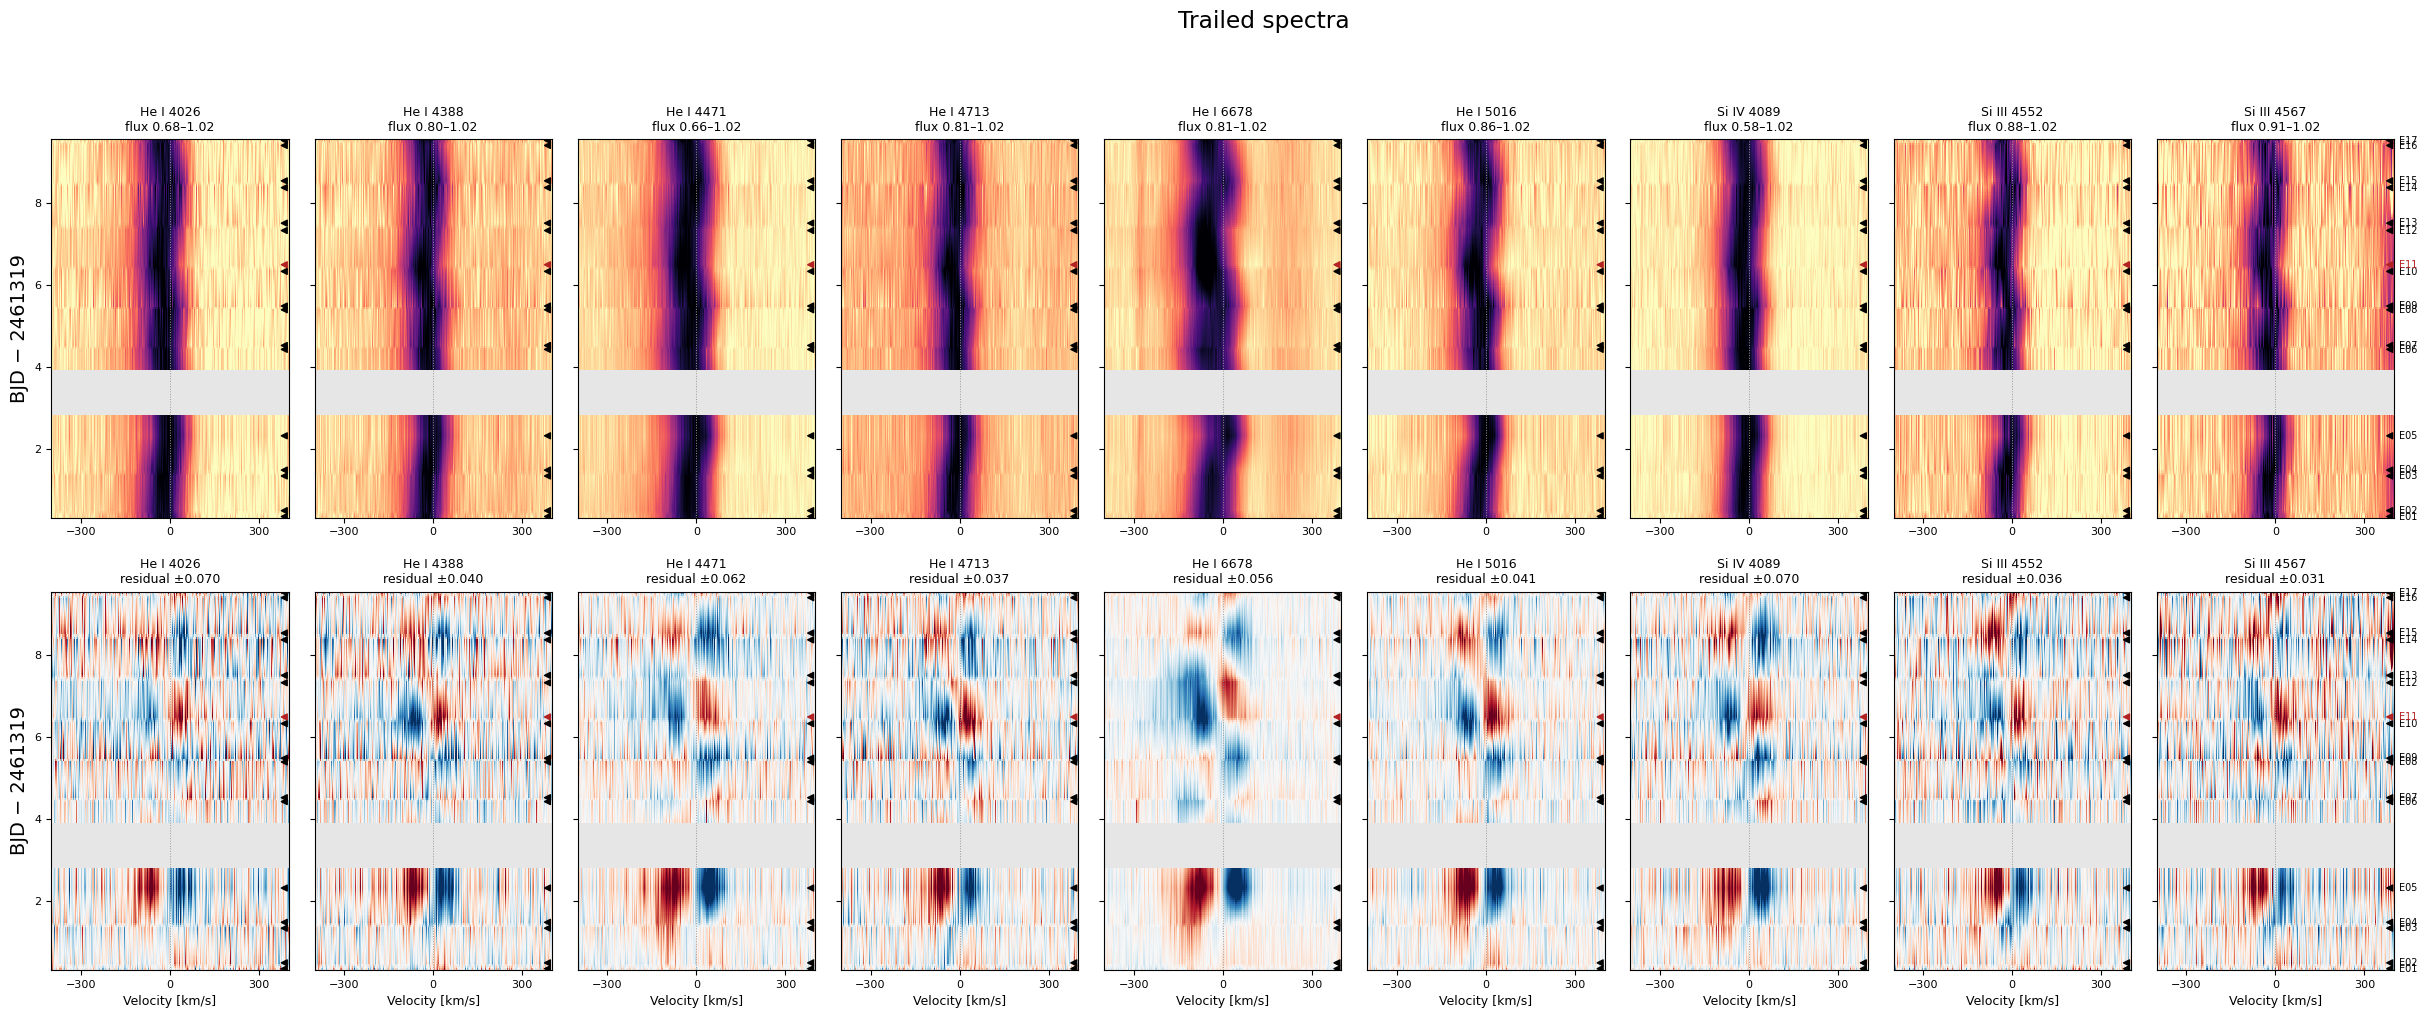

Grey = no real epoch within the fill distance. Residual = filled flux minus median of real epochs.


In [22]:
t0 = np.floor(bjd[0])
y_real = bjd - t0
colours = ["firebrick" if l == "E11" else "k" for l in labels]

x_edges = np.r_[grid[0] - DV / 2, 0.5 * (grid[1:] + grid[:-1]), grid[-1] + DV / 2]
dt = t_grid[1] - t_grid[0]
y_edges = np.r_[t_grid[0] - dt / 2, 0.5 * (t_grid[1:] + t_grid[:-1]),
                t_grid[-1] + dt / 2] - t0

names = list(LINES)
fig, axes = plt.subplots(len(ROWS), len(names),
                         figsize=(2.7 * len(names) + 1.2, 5.2 * len(ROWS)),
                         sharey=True, squeeze=False)

for col, name in enumerate(names):
    D = DYN[name]
    for row, kind in enumerate(ROWS):
        ax = axes[row, col]
        ax.set_facecolor("0.9")
        if not D["covered"]:
            ax.text(0.5, 0.5, "No coverage", transform=ax.transAxes, ha="center")
            ax.set_title(name, fontsize=9)
            continue

        if kind == "flux":
            low = np.nanpercentile(D["flux"], 1)
            ax.pcolormesh(x_edges, y_edges, np.ma.masked_invalid(D["filled"]),
                          cmap="magma", vmin=low, vmax=1.02, shading="flat")
            ax.set_title(f"{name}\nflux {low:.2f}–1.02", fontsize=9)
        elif kind == "residual":
            resid = D["filled_resid"]
            limit = (RESIDUAL_LIMIT if RESIDUAL_LIMIT is not None
                     else max(0.005, np.nanpercentile(np.abs(resid), 99)))
            ax.pcolormesh(x_edges, y_edges, np.ma.masked_invalid(resid),
                          cmap="RdBu_r", vmin=-limit, vmax=limit, shading="flat")
            ax.set_title(f"{name}\nresidual ±{limit:.3f}", fontsize=9)
        else:
            raise ValueError("ROWS entries must be 'flux' or 'residual'.")

        ax.scatter(np.full(len(bjd), VIEW_HALF - 15), y_real,
                   marker="<", c=colours, s=18, zorder=5)
        ax.axvline(0, color="0.6", lw=0.7, ls=":")
        ax.set_xlim(-VIEW_HALF, VIEW_HALF)
        ax.set_xticks([-300, 0, 300])
        ax.tick_params(labelsize=8)
        if row == len(ROWS) - 1:
            ax.set_xlabel("Velocity [km/s]", fontsize=9)
        if col == 0:
            ax.set_ylabel(f"BJD − {t0:.0f}")
        if col == len(names) - 1:
            for label, y, colour in zip(labels, y_real, colours):
                ax.text(VIEW_HALF + 15, y, label, color=colour, fontsize=7,
                        va="center", clip_on=False)

axes[0, 0].set_ylim(y_edges[0], y_edges[-1])
fig.suptitle("Trailed spectra")
fig.tight_layout(rect=(0, 0, 0.96, 0.95))
plt.show()
print("Grey = no real epoch within the fill distance. Residual = filled flux minus median of real epochs.")

,BJD,He I 6678,He I 5016,He I 4471,He I 4713,mean_lag,line_spread
E01,2461319.36,-44.66,-34.58,-25.28,-23.50,-32.01,9.74
E02,2461319.50,-48.77,-36.16,-26.95,-23.92,-33.95,11.17
E03,2461320.34,-40.76,-27.84,-23.30,-18.93,-27.71,9.43
E04,2461320.49,-36.45,-24.69,-20.54,-14.57,-24.06,9.24
E05,2461321.32,0.00,0.00,0.00,0.00,0.00,0.00
E06,2461323.43,-53.85,-33.51,-31.22,-22.05,-35.16,13.41
E07,2461323.53,-49.57,-30.31,-27.21,-18.94,-31.51,12.96
E08,2461324.40,-34.50,-18.89,-15.89,-10.72,-20.00,10.24
E09,2461324.49,-33.56,-18.89,-17.40,-11.60,-20.36,9.34
E10,2461325.33,-58.00,-50.01,-35.56,-35.65,-44.81,11.11


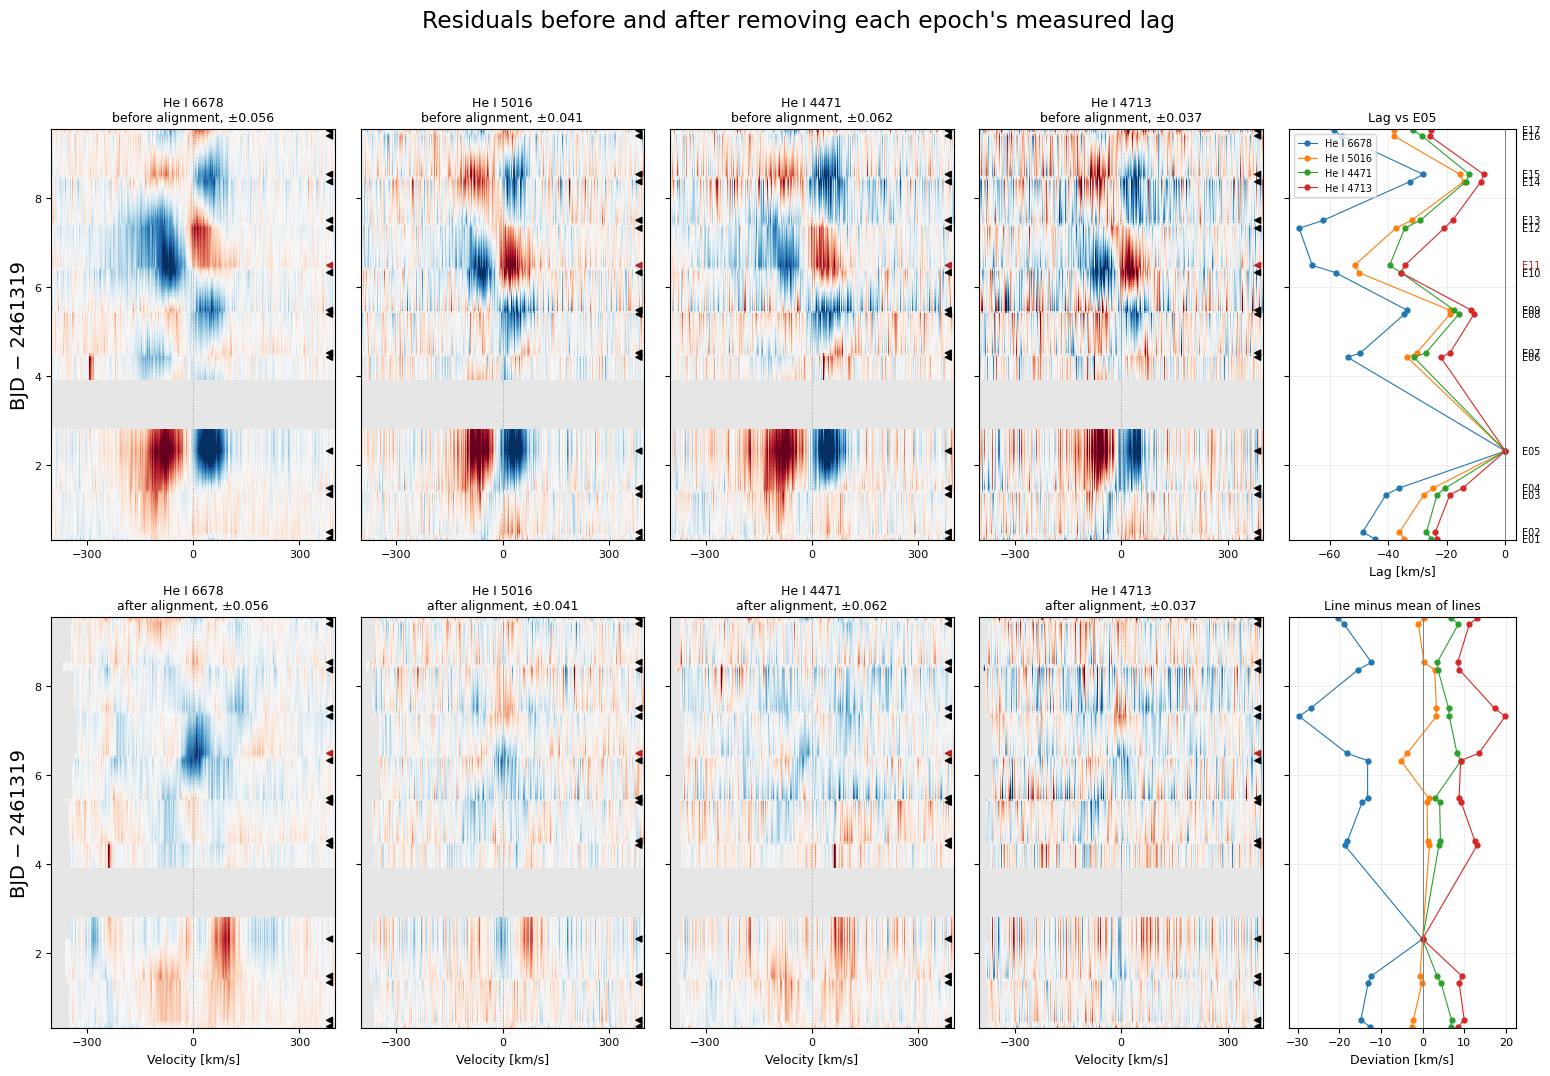

Positive lag = feature redward of the reference epoch. Residual = flux - median (red = less absorption).
Lags come from a fixed window with a free depth scale; no uncertainties are computed.


In [24]:
import warnings

CLEAN_LINES = ["He I 6678", "He I 5016", "He I 4471", "He I 4713"]
CORE_CENTRE = -27.0          # window used to measure lags [km/s]
CORE_HALF = 80
LAG_RANGE = 150.0
LAG_STEP = 1.0
REFERENCE_EPOCH = "E05"      # lags are relative to this epoch (its lag is 0)
N_ITER = 3                   # reference = aligned median after the first pass
LIMIT_FLOOR = 0.005

lag_grid = np.arange(-LAG_RANGE, LAG_RANGE + LAG_STEP, LAG_STEP)
core = np.abs(grid - CORE_CENTRE) <= CORE_HALF
ref_index = labels.index(REFERENCE_EPOCH)
n_epochs = len(labels)

ALIGN = {}
for name in CLEAN_LINES:
    flux = DYN[name]["flux"]
    absorption = 1.0 - flux
    ref = absorption[ref_index].copy()
    lags = np.zeros(n_epochs)
    at_bound = np.zeros(n_epochs, bool)

    for iteration in range(N_ITER):
        for i in range(n_epochs):
            y = absorption[i]
            rss = np.full(lag_grid.size, np.inf)
            for k, lag in enumerate(lag_grid):
                shifted = np.interp(grid - lag, grid, ref, left=np.nan, right=np.nan)
                ok = core & np.isfinite(y) & np.isfinite(shifted)
                if ok.sum() < 0.8 * core.sum():
                    continue
                denom = shifted[ok] @ shifted[ok]
                if denom <= 0:
                    continue
                scale = (y[ok] @ shifted[ok]) / denom        # free depth scale
                rss[k] = np.sum((y[ok] - scale * shifted[ok]) ** 2)

            if not np.isfinite(rss).any():
                lags[i] = np.nan
                continue
            k = int(np.argmin(rss))
            lags[i] = lag_grid[k]
            at_bound[i] = k in (0, lag_grid.size - 1)
            if 0 < k < lag_grid.size - 1 and np.isfinite(rss[k - 1]) and np.isfinite(rss[k + 1]):
                curvature = rss[k - 1] - 2 * rss[k] + rss[k + 1]
                if curvature > 0:                            # parabolic refinement
                    lags[i] += 0.5 * (rss[k - 1] - rss[k + 1]) / curvature * LAG_STEP

        lags -= lags[ref_index]
        aligned_abs = np.vstack([
            np.interp(grid + lags[i], grid, absorption[i], left=np.nan, right=np.nan)
            for i in range(n_epochs)
        ])
        with warnings.catch_warnings():
            warnings.simplefilter("ignore", RuntimeWarning)
            ref = np.nanmedian(aligned_abs, axis=0)

    # Aligned flux, residual from the aligned median, filled in time for display
    aligned_flux = np.vstack([
        np.interp(grid + lags[i], grid, flux[i], left=np.nan, right=np.nan)
        for i in range(n_epochs)
    ])
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", RuntimeWarning)
        median_aligned = np.nanmedian(aligned_flux, axis=0)
    resid = aligned_flux - median_aligned
    filled = (1 - weight)[:, None] * resid[lo] + weight[:, None] * resid[hi]
    filled[too_far] = np.nan
    ALIGN[name] = {"lags": lags.copy(), "at_bound": at_bound, "filled_resid": filled}

# Lag table: do the lines agree?
LAG_TABLE = pd.DataFrame({n: ALIGN[n]["lags"] for n in CLEAN_LINES}, index=labels)
LAG_TABLE.insert(0, "BJD", bjd)
LAG_TABLE["mean_lag"] = LAG_TABLE[CLEAN_LINES].mean(axis=1)
LAG_TABLE["line_spread"] = LAG_TABLE[CLEAN_LINES].std(axis=1, ddof=1)
display(LAG_TABLE.round(2))
for n in CLEAN_LINES:
    hit = [l for l, b in zip(labels, ALIGN[n]["at_bound"]) if b]
    if hit:
        print(f"{n}: lag at the search bound for {hit}; increase LAG_RANGE.")

# Figure: residual before vs after alignment, plus the lag curves
t0 = np.floor(bjd[0])
y_real = bjd - t0
colours = ["firebrick" if l == "E11" else "k" for l in labels]
x_edges = np.r_[grid[0] - DV / 2, 0.5 * (grid[1:] + grid[:-1]), grid[-1] + DV / 2]
dt = t_grid[1] - t_grid[0]
y_edges = np.r_[t_grid[0] - dt / 2, 0.5 * (t_grid[1:] + t_grid[:-1]),
                t_grid[-1] + dt / 2] - t0

n_lines = len(CLEAN_LINES)
fig, axes = plt.subplots(2, n_lines + 1, figsize=(3.0 * n_lines + 4.2, 11),
                         sharey=True, squeeze=False,
                         gridspec_kw={"width_ratios": [1] * n_lines + [0.8]})

for col, name in enumerate(CLEAN_LINES):
    before = DYN[name]["filled_resid"]
    after = ALIGN[name]["filled_resid"]
    limit = max(LIMIT_FLOOR, np.nanpercentile(np.abs(before), 99))   # same scale for both
    for row, (data, tag) in enumerate([(before, "before alignment"), (after, "after alignment")]):
        ax = axes[row, col]
        ax.set_facecolor("0.9")
        ax.pcolormesh(x_edges, y_edges, np.ma.masked_invalid(data), cmap="RdBu_r",
                      vmin=-limit, vmax=limit, shading="flat")
        ax.scatter(np.full(n_epochs, VIEW_HALF - 15), y_real, marker="<", c=colours,
                   s=18, zorder=5)
        ax.axvline(0, color="0.6", lw=0.7, ls=":")
        ax.set_xlim(-VIEW_HALF, VIEW_HALF)
        ax.set_xticks([-300, 0, 300])
        ax.tick_params(labelsize=8)
        ax.set_title(f"{name}\n{tag}, ±{limit:.3f}", fontsize=9)
        if row == 1:
            ax.set_xlabel("Velocity [km/s]", fontsize=9)
        if col == 0:
            ax.set_ylabel(f"BJD − {t0:.0f}")

lag_ax, dev_ax = axes[0, -1], axes[1, -1]
mean_lag = LAG_TABLE["mean_lag"].to_numpy()
for name in CLEAN_LINES:
    lag_ax.plot(ALIGN[name]["lags"], y_real, "o-", ms=3.5, lw=0.8, label=name)
    dev_ax.plot(ALIGN[name]["lags"] - mean_lag, y_real, "o-", ms=3.5, lw=0.8)
for ax, title, xlabel in [(lag_ax, f"Lag vs {REFERENCE_EPOCH}", "Lag [km/s]"),
                          (dev_ax, "Line minus mean of lines", "Deviation [km/s]")]:
    ax.axvline(0, color="0.5", lw=0.7)
    ax.set_title(title, fontsize=9)
    ax.set_xlabel(xlabel, fontsize=9)
    ax.grid(alpha=0.2)
    ax.tick_params(labelsize=8)
lag_ax.legend(fontsize=7)
for label, y, colour in zip(labels, y_real, colours):
    lag_ax.text(1.03, y, label, color=colour, fontsize=7, va="center", clip_on=False,
                transform=lag_ax.get_yaxis_transform())

axes[0, 0].set_ylim(y_edges[0], y_edges[-1])
fig.suptitle("Residuals before and after removing each epoch's measured lag")
fig.tight_layout(rect=(0, 0, 0.97, 0.96))
plt.show()
print("Positive lag = feature redward of the reference epoch. Residual = flux - median (red = less absorption).")
print("Lags come from a fixed window with a free depth scale; no uncertainties are computed.")